In [ ]:
import json
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded_shelves = files.upload()

Saving shelves.json to shelves.json


In [ ]:
shelf_file = list(uploaded_shelves.keys())[0]

with open(shelf_file, "r") as f:
    shelf_data = json.load(f)

print("Shelf data loaded successfully!")
print("Number of shelves:", len(shelf_data))

Shelf data loaded successfully!
Number of shelves: 7


In [ ]:
uploaded_gaps = files.upload()

Saving gaps.json to gaps.json


In [ ]:
gap_file = list(uploaded_gaps.keys())[0]

with open(gap_file, "r") as f:
    gap_data = json.load(f)

print("Gap data loaded successfully!")
print("Candidate gaps:", len(gap_data["candidate_gaps"]))

Gap data loaded successfully!
Candidate gaps: 6


In [ ]:
print("CANDIDATE GAPS")
print("=" * 50)

for i, gap in enumerate(gap_data["candidate_gaps"], start=1):

    print(
        f"Gap {i}: "
        f"Shelf {gap['shelf_id']} | "
        f"Size = {gap['gap']:.1f} px"
    )

CANDIDATE GAPS
Gap 1: Shelf 1 | Size = 218.5 px
Gap 2: Shelf 1 | Size = 23.8 px
Gap 3: Shelf 5 | Size = 54.9 px
Gap 4: Shelf 6 | Size = 91.1 px
Gap 5: Shelf 6 | Size = 35.0 px
Gap 6: Shelf 7 | Size = 320.9 px


In [ ]:
for shelf in shelf_data:

    widths = [
        product["width"]
        for product in shelf["products"]
    ]

    shelf["median_product_width"] = float(
        np.median(widths)
    )

print("Typical product width calculated for each shelf.")

for shelf in shelf_data:
    print(
        f"Shelf {shelf['shelf_id']}: "
        f"{shelf['median_product_width']:.1f} px"
    )

Typical product width calculated for each shelf.
Shelf 1: 20.6 px
Shelf 2: 18.7 px
Shelf 3: 19.9 px
Shelf 4: 22.3 px
Shelf 5: 22.1 px
Shelf 6: 22.3 px
Shelf 7: 19.2 px


In [ ]:
missing_candidates = []

for gap in gap_data["candidate_gaps"]:

    shelf = next(
        shelf for shelf in shelf_data
        if shelf["shelf_id"] == gap["shelf_id"]
    )

    typical_width = shelf["median_product_width"]

    estimated_products = gap["gap"] / typical_width

    missing_candidates.append({
        "shelf_id": gap["shelf_id"],
        "gap": gap["gap"],
        "typical_product_width": typical_width,
        "estimated_products": float(estimated_products)
    })

print("Estimated missing-product quantities calculated.")

Estimated missing-product quantities calculated.


In [ ]:
print("MISSING PRODUCT ESTIMATES")
print("=" * 55)

for i, candidate in enumerate(missing_candidates, start=1):

    print(
        f"Gap {i}: "
        f"Shelf {candidate['shelf_id']} | "
        f"Gap = {candidate['gap']:.1f}px | "
        f"Typical width = {candidate['typical_product_width']:.1f}px | "
        f"Estimated missing = "
        f"{candidate['estimated_products']:.2f}"
    )

MISSING PRODUCT ESTIMATES
Gap 1: Shelf 1 | Gap = 218.5px | Typical width = 20.6px | Estimated missing = 10.59
Gap 2: Shelf 1 | Gap = 23.8px | Typical width = 20.6px | Estimated missing = 1.15
Gap 3: Shelf 5 | Gap = 54.9px | Typical width = 22.1px | Estimated missing = 2.49
Gap 4: Shelf 6 | Gap = 91.1px | Typical width = 22.3px | Estimated missing = 4.09
Gap 5: Shelf 6 | Gap = 35.0px | Typical width = 22.3px | Estimated missing = 1.57
Gap 6: Shelf 7 | Gap = 320.9px | Typical width = 19.2px | Estimated missing = 16.70


In [ ]:
for candidate in missing_candidates:

    estimated = candidate["estimated_products"]

    if estimated >= 0.75:
        candidate["status"] = "Potential Missing Product"
    else:
        candidate["status"] = "Small Gap"

print("Gap classification completed.")

Gap classification completed.


In [ ]:
print("POTENTIAL MISSING PRODUCTS")
print("=" * 50)

potential_missing = [
    candidate
    for candidate in missing_candidates
    if candidate["status"] == "Potential Missing Product"
]

if len(potential_missing) == 0:

    print("No potential missing products detected.")

else:

    for i, candidate in enumerate(potential_missing, start=1):

        print(
            f"{i}. "
            f"Shelf {candidate['shelf_id']} | "
            f"Gap = {candidate['gap']:.1f}px | "
            f"Estimated missing = "
            f"{candidate['estimated_products']:.2f}"
        )

POTENTIAL MISSING PRODUCTS
1. Shelf 1 | Gap = 218.5px | Estimated missing = 10.59
2. Shelf 1 | Gap = 23.8px | Estimated missing = 1.15
3. Shelf 5 | Gap = 54.9px | Estimated missing = 2.49
4. Shelf 6 | Gap = 91.1px | Estimated missing = 4.09
5. Shelf 6 | Gap = 35.0px | Estimated missing = 1.57
6. Shelf 7 | Gap = 320.9px | Estimated missing = 16.70


In [ ]:
uploaded_image = files.upload()

Saving self1.jpg to self1.jpg


Image loaded successfully!


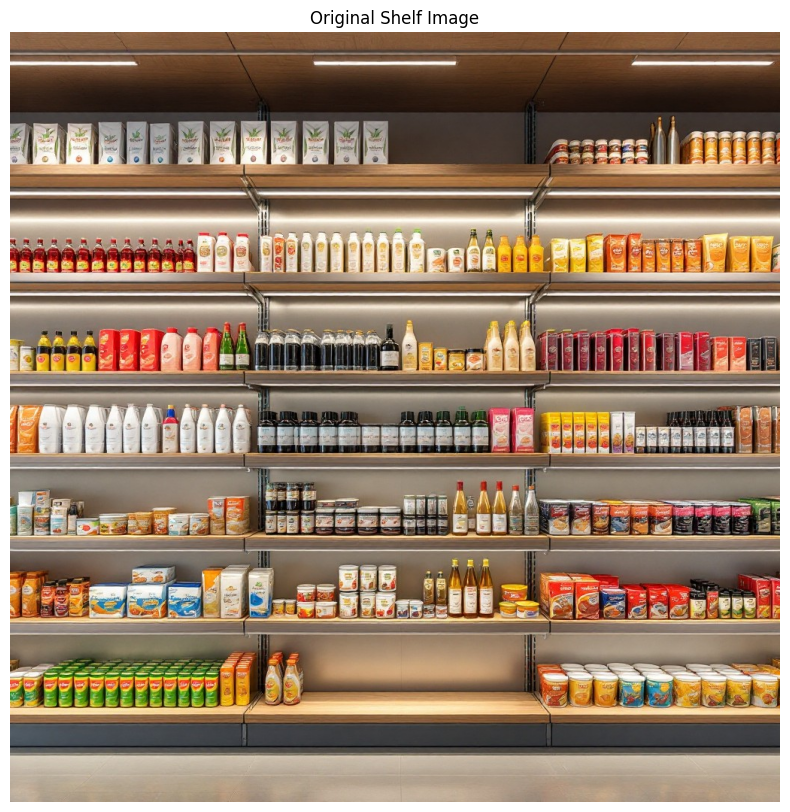

In [ ]:
image_name = list(uploaded_image.keys())[0]

image = cv2.imread(
    os.path.join("/content", image_name)
)

if image is None:
    raise ValueError("Could not load image.")

print("Image loaded successfully!")

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 10))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Original Shelf Image")
plt.show()

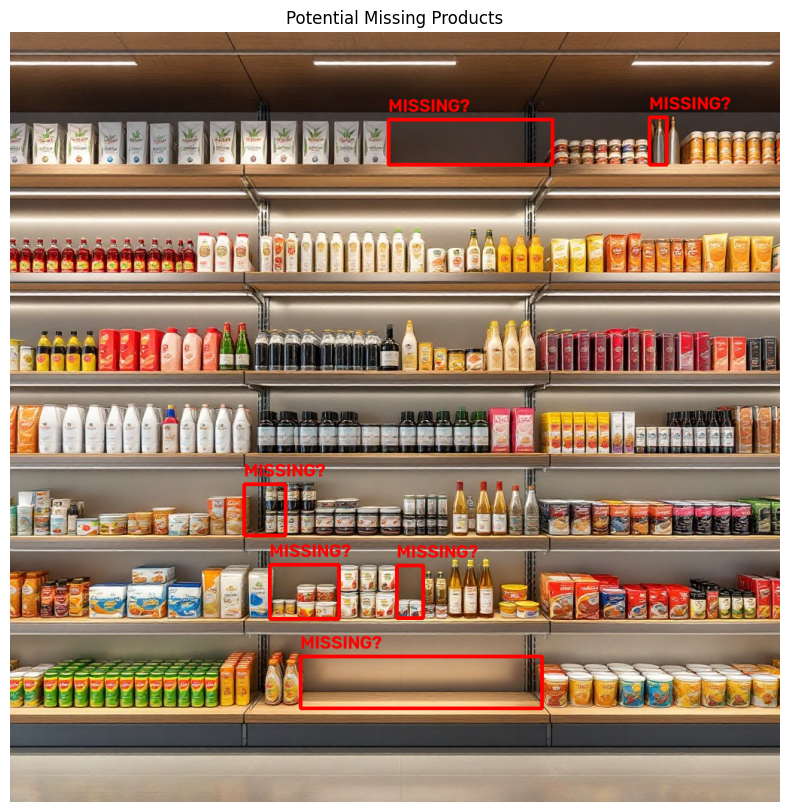

In [ ]:
missing_image = image.copy()

for i, candidate in enumerate(potential_missing, start=1):

    shelf = next(
        shelf for shelf in shelf_data
        if shelf["shelf_id"] == candidate["shelf_id"]
    )

    products = sorted(
        shelf["products"],
        key=lambda d: d["center_x"]
    )

    # Find the corresponding gap
    matching_gap = next(
        gap for gap in gap_data["candidate_gaps"]
        if (
            gap["shelf_id"] == candidate["shelf_id"]
            and abs(gap["gap"] - candidate["gap"]) < 0.001
        )
    )

    left_product = products[
        matching_gap["left_product_index"]
    ]

    right_product = products[
        matching_gap["right_product_index"]
    ]

    x1 = int(left_product["x2"])
    x2 = int(right_product["x1"])

    y1 = int(
        min(
            left_product["y1"],
            right_product["y1"]
        )
    )

    y2 = int(
        max(
            left_product["y2"],
            right_product["y2"]
        )
    )

    # Draw missing-product candidate box
    cv2.rectangle(
        missing_image,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        3
    )

    cv2.putText(
        missing_image,
        "MISSING?",
        (x1, max(30, y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2
    )

missing_rgb = cv2.cvtColor(
    missing_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 10))
plt.imshow(missing_rgb)
plt.axis("off")
plt.title("Potential Missing Products")
plt.show()

In [ ]:
summary = {
    "total_shelves": len(shelf_data),
    "total_candidate_gaps": len(gap_data["candidate_gaps"]),
    "potential_missing_products": len(potential_missing),
    "details": potential_missing
}

print("FINAL SUMMARY")
print("=" * 40)

print("Total shelves:", summary["total_shelves"])
print("Candidate gaps:", summary["total_candidate_gaps"])
print(
    "Potential missing products:",
    summary["potential_missing_products"]
)

FINAL SUMMARY
Total shelves: 7
Candidate gaps: 6
Potential missing products: 6


In [ ]:
output_path = "/content/missing_products.json"

with open(output_path, "w") as f:
    json.dump(summary, f, indent=4)

print("Results saved to:")
print(output_path)

Results saved to:
/content/missing_products.json


In [ ]:
files.download("/content/missing_products.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>